<h2 style="margin-bottom: 10px;"><b>Causal Inference Project</b></h2>
<h3 style="margin-top: 0;">Measuring the Impact of the 2017 Equifax Security Breach</h3>

In [1]:
import pandas as pd
import numpy as np
import matplotlib.dates as md
import matplotlib.pyplot as plt

### Visualizing Equifax stock price (2017)

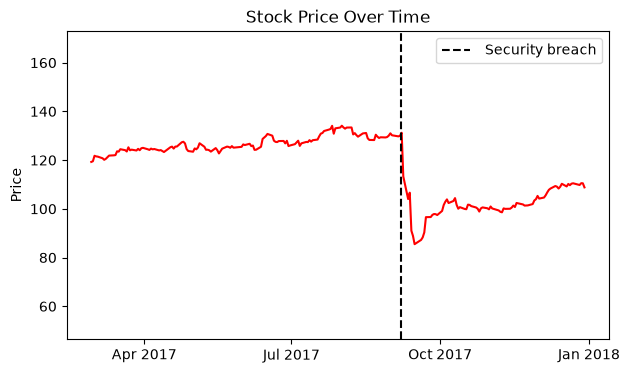

In [2]:
import yfinance as yf

# Get Stock Data
equifax = yf.Ticker("EFX").history(start="2017-2-27", end="2018-01-01")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(equifax.index, equifax["Close"], color="red")
ax.margins(x=0.05,y=0.8)  # zooming out
ax.xaxis.set_major_locator(md.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(md.DateFormatter("%b %Y"))
ax.axvline(pd.Timestamp("2017-09-07"), color="black", linestyle="--", label=" Security breach")
ax.set_ylabel("Price")
ax.set_title("Stock Price Over Time")
ax.legend()
plt.show()

#### Following the late 2017 security breach, Equifax's stock price dropped by roughly $40. While the graph shows an initial recovery as the stock price started going back up, this visual alone can be deceptive. 
#### During that same period, the entire market including the S&P 500 and Equifax's competitors was in a strong bull. This highlights why we need to study the treatment effect, and to look at the causal a **synthetic control model**, to isolate the actual impact of the breach from general market trends.
#### For reference, competitors' stocks were indeed booming, as the first graph on the left below illustrates:

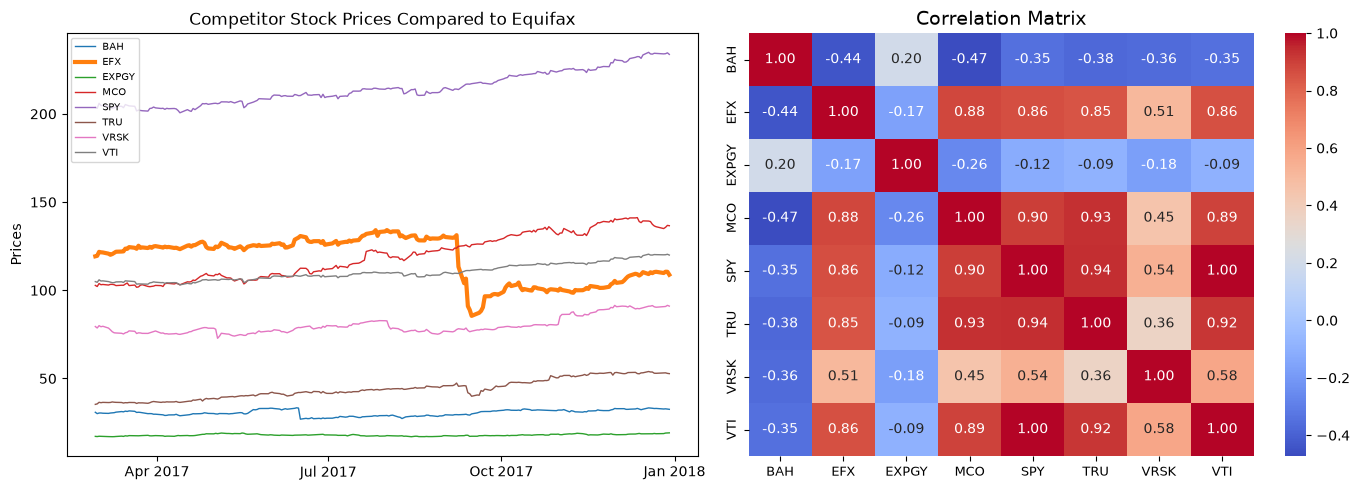

In [11]:
competitors = ["BAH", "EFX", "EXPGY", "MCO", "SPY", "TRU", "VRSK", "VTI"]

prices = pd.DataFrame()
for ticker in competitors:
    data = yf.Ticker(ticker).history(start="2017-02-27", end="2018-01-01")
    prices[ticker] = data["Close"]

prices = prices.reset_index()

treatment_date = pd.Timestamp("2017-09-07", tz=prices["Date"].dt.tz)
pre_treatment_prices = prices[prices["Date"] <= treatment_date]
corr_plot = pre_treatment_prices.set_index("Date").corr()

import seaborn as sns
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
for ticker in competitors:
    if ticker == "EFX":
        ax1.plot(prices["Date"], prices[ticker], label=ticker, linewidth=3)
    else:
        ax1.plot(prices["Date"], prices[ticker], label=ticker, linewidth=1.0)

ax1.xaxis.set_major_locator(md.MonthLocator(bymonth=[1, 4, 7, 10]))
ax1.xaxis.set_major_formatter(md.DateFormatter("%b %Y"))
ax1.legend(fontsize="x-small", loc="upper left")
ax1.set_ylabel("Prices")
ax1.set_title("Competitor Stock Prices Compared to Equifax")

sns.heatmap(corr_plot, annot=True, cmap="coolwarm", fmt=".2f", ax=ax2)
ax2.set_xticklabels(ax2.get_xticklabels(), fontsize=9.5)
ax2.set_yticklabels(ax2.get_yticklabels(), fontsize=9.5)
ax2.set_title("Correlation Matrix", fontsize=14)

plt.tight_layout()
plt.show()

#### Based on the Correlation Matrix, we will drop the "BAH" and "EXPGY" from our donor pool, since they exhibit a negative correlation with the Equifax stock. Dropping them ensures that the synthetic control is constructed only from units that share directional trends with the treated unit.

### Modeling Synthetic Control

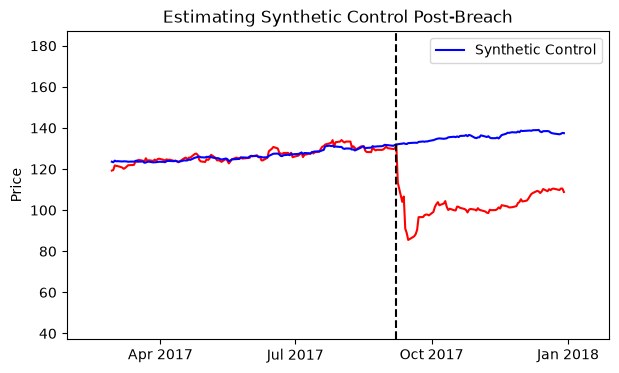

In [ ]:
donor_pool = [t for t in competitors if t not in ["EFX", "BAH", "EXPGY"]]
X = pre_treatment_prices[donor_pool].values
y = pre_treatment_prices["EFX"].values

from sklearn.linear_model import LassoCV
model = LassoCV(cv=5, positive=True, random_state=42)
model.fit(X, y)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(equifax.index, equifax["Close"], color="red")
ax.margins(x=0.1,y=0.9) 
ax.xaxis.set_major_locator(md.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(md.DateFormatter("%b %Y"))
ax.plot(prices["Date"], model.predict(prices[donor_pool].values), color="blue", label="Synthetic Control")
ax.axvline(treatment_date, color="black", linestyle="--")
ax.set_ylabel("Price")
ax.set_title("Estimating Synthetic Control Post-Breach")
ax.legend()
plt.show()

#### This synthetic control estimates Equifax’s stock price trajectory if the security breach had never occurred. While the synthetic control continues to grow post-breach, Equifax’s actual stock shows a slight upward tick. However, looking at Equifax alone is misleading; it creates the false impression that the stock is recovering and the crisis has passed. In reality, because the broader market and competitor stocks were booming, the true impact is a massive gap of up to $40 per share that a simple price chart completely misses.

### Modeling Synthetic Control using CausalPy's API

Initializing NUTS using jitter+adapt_diag...
Multiprocess sampling (4 chains in 4 jobs)
NUTS: [beta, y_hat_sigma]


c:\Users\User\Equifax-CI\.venv\Lib\site-packages\rich\live.py:260: UserWarning: install "ipywidgets" for Jupyter 
support
  warnings.warn('install "ipywidgets" for Jupyter support')

Sampling 4 chains for 1_000 tune and 1_000 draw iterations (4_000 + 4_000 draws total) took 37 seconds.
There were 354 divergences after tuning. Increase `target_accept` or reparameterize.
The rhat statistic is larger than 1.01 for some parameters. This indicates problems during sampling. See https://arxiv.org/abs/1903.08008 for details
The effective sample size per chain is smaller than 100 for some parameters.  A higher number is needed for reliable rhat and ess computation. See https://arxiv.org/abs/1903.08008 for details
Sampling: [beta, y_hat, y_hat_sigma]
Sampling: [y_hat]
Sampling: [y_hat]
Sampling: [y_hat]
Sampling: [y_hat]


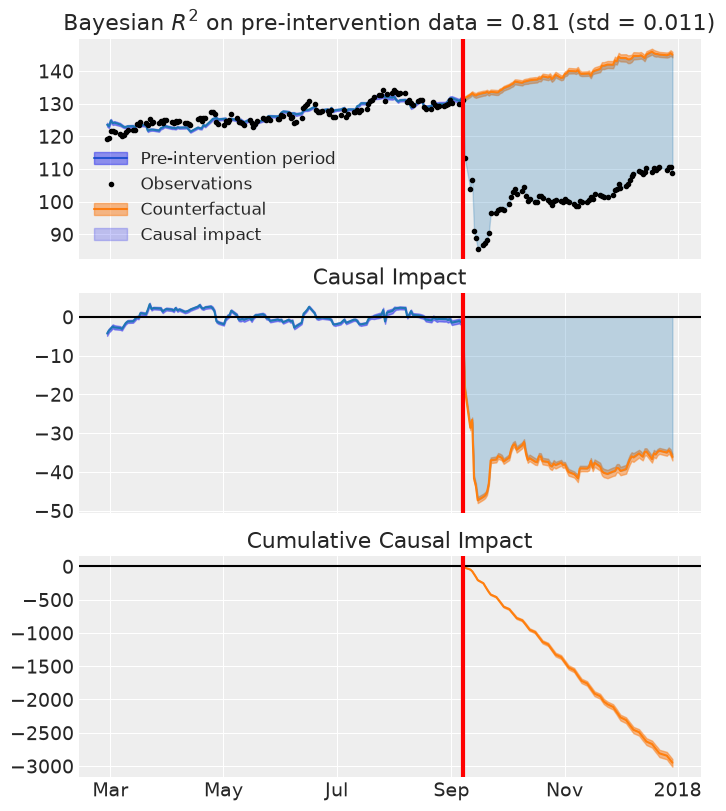

<Figure size 640x480 with 0 Axes>

In [15]:
import causalpy as cp

prices_copy = prices.copy()
prices_copy = prices_copy.set_index("Date")

sc_model = cp.SyntheticControl(
    data=prices_copy,
    treatment_time=pd.Timestamp("2017-09-07", tz=prices["Date"].dt.tz),
    treated_units=["EFX"],
    control_units=donor_pool,
)

fig, ax = sc_model.plot()
plt.tight_layout()
plt.show()

#### **Comment on the upper graph**
#### The third panel shows the cumulative causal impact over the months due to the persistent gap, reaching $\$3,000$ per share, which represents the total economic impact caused by the breach.

### Placebo Test

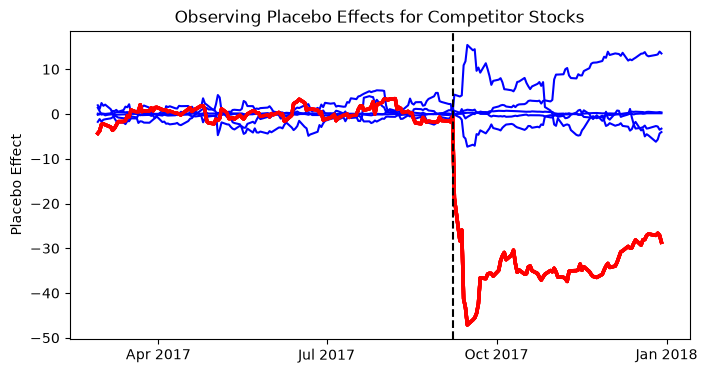

In [27]:
donor_pool = [t for t in competitors if t not in ["EFX", "BAH", "EXPGY"]]
estimated_placebo_effects = pd.DataFrame(index=prices_copy.index)

X_efx = pre_treatment_prices[donor_pool].values
y_efx = pre_treatment_prices["EFX"].values
efx_model = LassoCV(cv=5, positive=True, random_state=42)
efx_model.fit(X_efx, y_efx)

estimated_placebo_effects["EFX"] = (prices_copy["EFX"].values - efx_model.predict(prices_copy[donor_pool].values))

for treated_unit in donor_pool:
    donor_pool_pt = [t for t in donor_pool if t != treated_unit]
    X_pt = pre_treatment_prices[donor_pool_pt].values
    y_pt = pre_treatment_prices[treated_unit].values
    model = LassoCV(cv=5, positive=True, random_state=42)
    model.fit(X_pt, y_pt)
    estimated_placebo_effects[treated_unit] = prices_copy[treated_unit].values - model.predict(prices[donor_pool_pt].values)


fig, ax = plt.subplots(figsize=(8, 4))
for col in estimated_placebo_effects.columns:
    ax.plot(
        estimated_placebo_effects.index,
        estimated_placebo_effects[col],
        color="blue"
        )
    ax.plot(
        prices_copy.index,
        estimated_placebo_effects["EFX"],
        color="red",
        linewidth=2.5,
        )

ax.axvline(treatment_date, color="black", linestyle="--")
ax.xaxis.set_major_locator(md.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(md.DateFormatter("%b %Y"))
ax.set_ylabel("Placebo Effect")
ax.set_title("Observing Placebo Effects for Competitor Stocks")
plt.show()

#### The placebo test proves our model is reliable: control stocks (blue) stay near zero. This confirms the multi-week stock crash was a genuine, statistically significant impact of the data breach.